In [ ]:
import xarray as xr 
import numpy as np  

from scipy.spatial import cKDTree

import matplotlib as mpl
import matplotlib.pyplot as plt

import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from datetime import datetime

: 

In [2]:
ds = xr.open_dataset('/glade/work/fredc/cesm/grid/MOM6/NWA12/NWA12_grid.nc')

In [3]:
ds

<xarray.Dataset>
Dimensions:  (ny: 780, nx: 740, nxp: 741, nyp: 781)
Dimensions without coordinates: ny, nx, nxp, nyp
Data variables: (12/20)
    tlon     (ny, nx) float64 ...
    tlat     (ny, nx) float64 ...
    ulon     (ny, nxp) float64 ...
    ulat     (ny, nxp) float64 ...
    vlon     (nyp, nx) float64 ...
    vlat     (nyp, nx) float64 ...
    ...       ...
    tarea    (ny, nx) float64 ...
    tmask    (ny, nx) float64 ...
    angle    (ny, nx) float64 ...
    depth    (ny, nx) float64 ...
    ar       (ny, nx) float64 ...
    egs      (ny, nx) float64 ...
Attributes:
    Description:  MOM6 NCAR NWA12 grid (ORCA type)
    Author:       Fred Castruccio (fredc@ucar.edu)
    Created:      2024-04-18T08:45:05.683854
    type:         NWA12v1 file

In [4]:
from matplotlib import colors
cmap = np.loadtxt('/glade/u/home/fredc/python/cmap/nrl.cmap')
cmap = colors.ListedColormap(cmap)

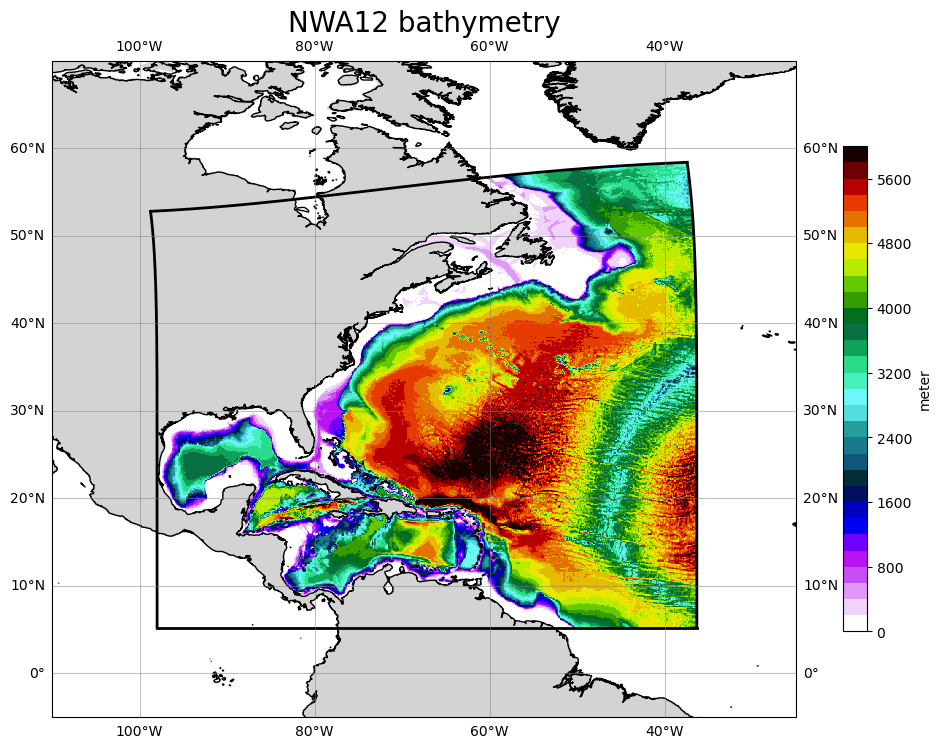

In [5]:
plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

'/glade/u/home/fredc/python/cmap/nrl.cmap'

cmin=0
cmax=6000
n=31
clevs=np.linspace(cmin,cmax,n)
norm=mpl.colors.BoundaryNorm(clevs, ncolors=cmap.N)

im = ax.pcolormesh(ds.tlon, ds.tlat, ds.depth.where(ds.depth!=0), transform=ccrs.PlateCarree(), cmap=cmap, norm=norm)
plt.colorbar(im, shrink=0.7, label=r'meter')

ax.plot(ds.qlon[0,:], ds.qlat[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[-1,:], ds.qlat[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[:,0], ds.qlat[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[:,-1], ds.qlat[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())


plt.title('NWA12 bathymetry', fontsize=20)

plt.savefig('/glade/work/fredc/cesm/grid/MOM6/NWA12/Plots/NWA12_topo.png', dpi=300, facecolor='w', edgecolor='w', orientation='portrait')

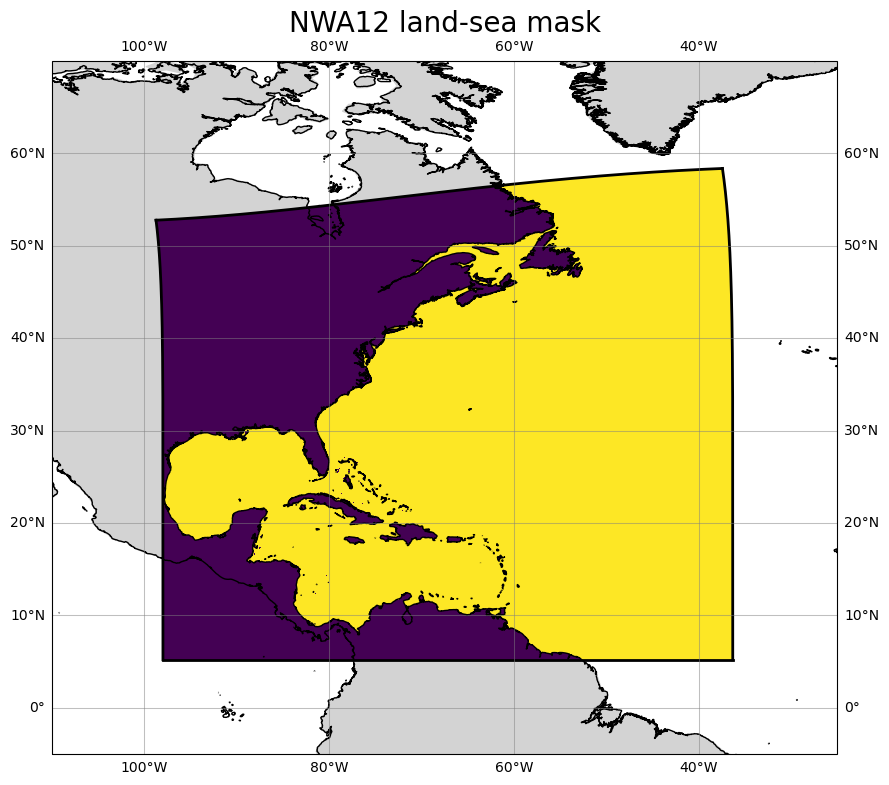

In [6]:
plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)


im = ax.pcolormesh(ds.tlon, ds.tlat, ds.tmask, transform=ccrs.PlateCarree())
#plt.colorbar(im, shrink=0.7, label=r'meter')

ax.plot(ds.qlon[0,:], ds.qlat[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[-1,:], ds.qlat[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[:,0], ds.qlat[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[:,-1], ds.qlat[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())


plt.title('NWA12 land-sea mask', fontsize=20)

plt.savefig('/glade/work/fredc/cesm/grid/MOM6/NWA12/Plots/NWA12_mask.png', dpi=300, facecolor='w', edgecolor='w', orientation='portrait')

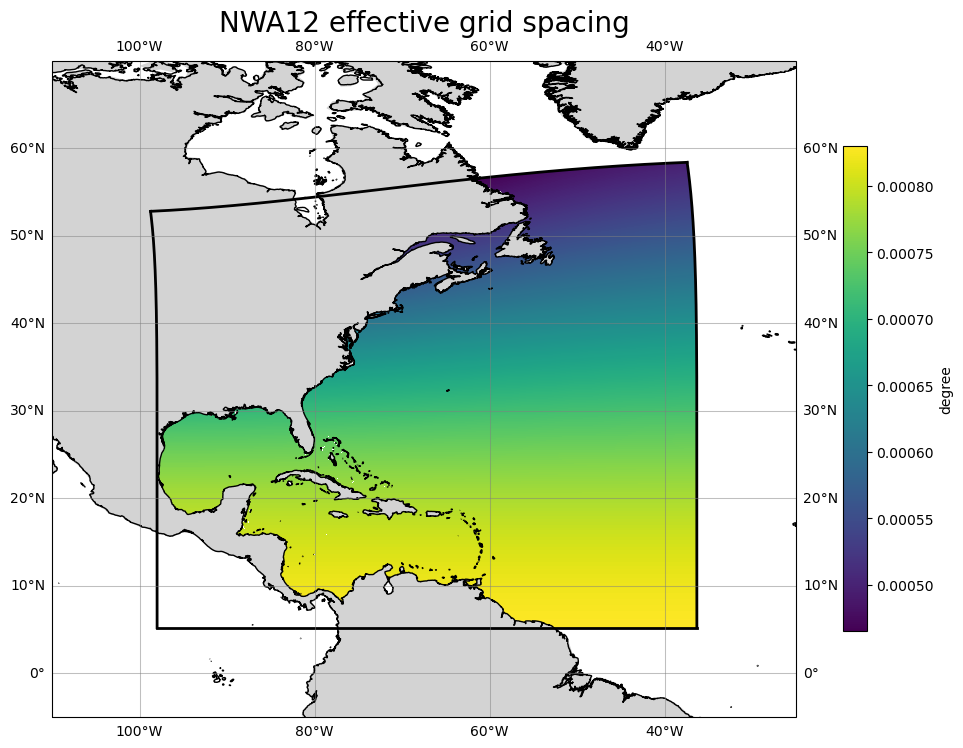

In [7]:
plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)


im = ax.pcolormesh(ds.tlon, ds.tlat, ds.egs.where(ds.tmask==1), transform=ccrs.PlateCarree())
plt.colorbar(im, shrink=0.7, label=r'degree')

ax.plot(ds.qlon[0,:], ds.qlat[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[-1,:], ds.qlat[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[:,0], ds.qlat[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[:,-1], ds.qlat[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())


plt.title('NWA12 effective grid spacing', fontsize=20)

plt.savefig('/glade/work/fredc/cesm/grid/MOM6/NWA12/Plots/NWA12_egs.png', dpi=300, facecolor='w', edgecolor='w', orientation='portrait')

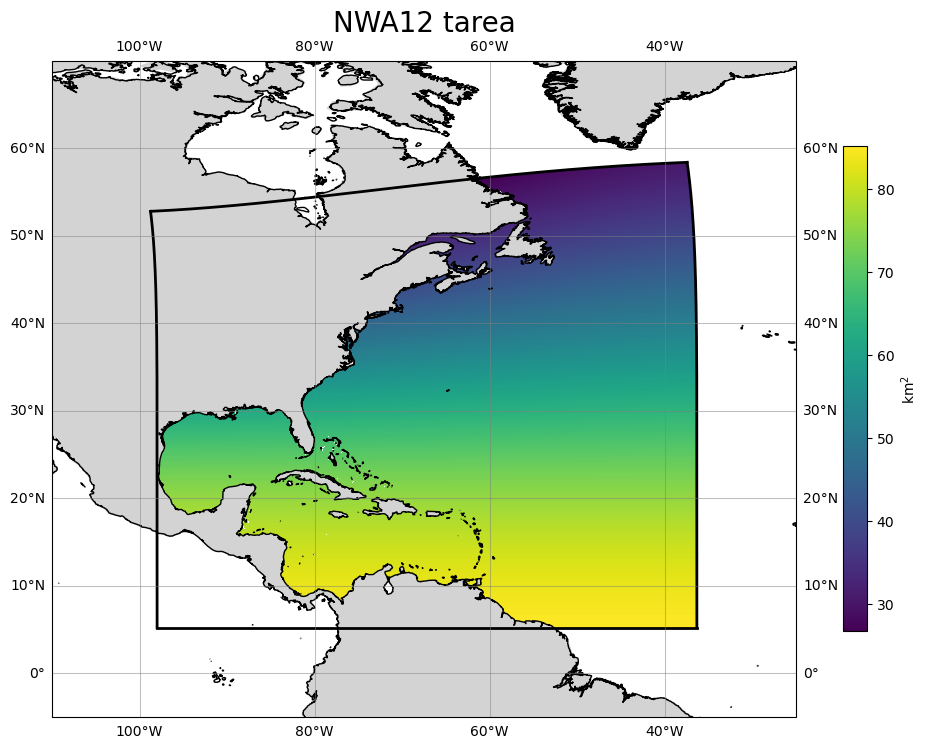

In [8]:
plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)


im = ax.pcolormesh(ds.tlon, ds.tlat, ds.tarea.where(ds.tmask==1)/1e6, transform=ccrs.PlateCarree())
plt.colorbar(im, shrink=0.7, label=r'km$^2$')

ax.plot(ds.qlon[0,:], ds.qlat[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[-1,:], ds.qlat[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[:,0], ds.qlat[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[:,-1], ds.qlat[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())


plt.title('NWA12 tarea', fontsize=20)

plt.savefig('/glade/work/fredc/cesm/grid/MOM6/NWA12/Plots/NWA12_tarea.png', dpi=300, facecolor='w', edgecolor='w', orientation='portrait')

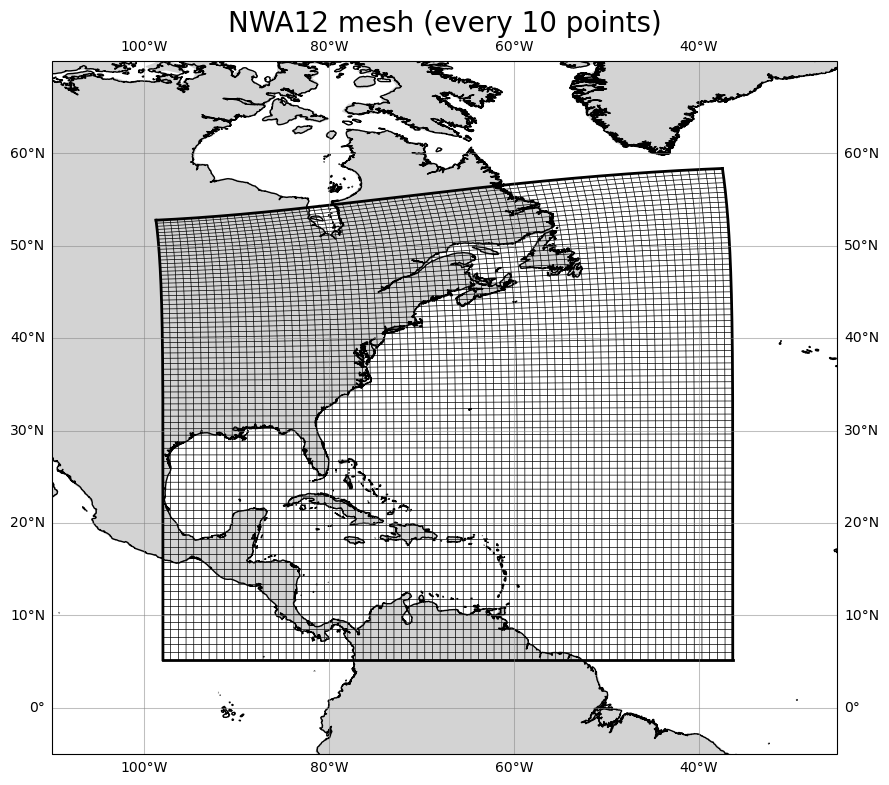

In [9]:
plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(ds.qlon[::k,::k], ds.qlat[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(ds.qlon[::k,::k].T, ds.qlat[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(ds.qlon[0,:], ds.qlat[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[-1,:], ds.qlat[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[:,0], ds.qlat[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[:,-1], ds.qlat[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)

plt.savefig('/glade/work/fredc/cesm/grid/MOM6/NWA12/Plots/NWA12_mesh.png', dpi=300, facecolor='w', edgecolor='w', orientation='portrait')

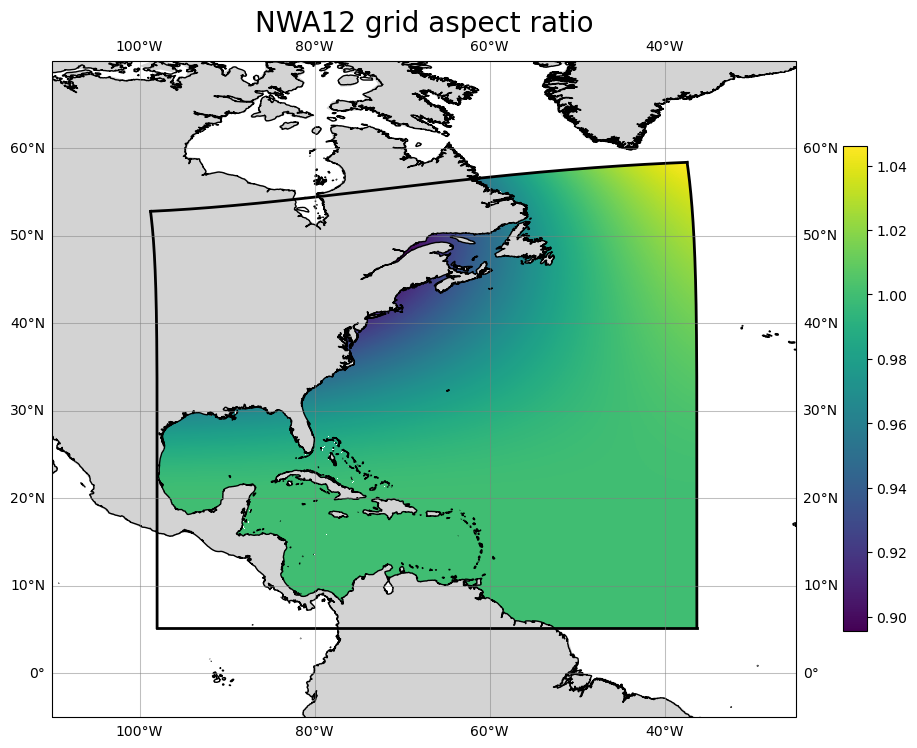

In [10]:
plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)


im = ax.pcolormesh(ds.tlon, ds.tlat, ds.ar.where(ds.tmask==1), transform=ccrs.PlateCarree())
plt.colorbar(im, shrink=0.7)

ax.plot(ds.qlon[0,:], ds.qlat[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[-1,:], ds.qlat[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[:,0], ds.qlat[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[:,-1], ds.qlat[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())


plt.title('NWA12 grid aspect ratio', fontsize=20)

plt.savefig('/glade/work/fredc/cesm/grid/MOM6/NWA12/Plots/NWA12_aspect_ratio.png', dpi=300, facecolor='w', edgecolor='w', orientation='portrait')

In [11]:
ds2 = xr.open_dataset('/glade/work/fredc/cesm/grid/MOM6/NWA12/GFDL/NWA12_grid.nc')

Text(0.5, 1.0, 'NWA12 GFDL land-sea mask')

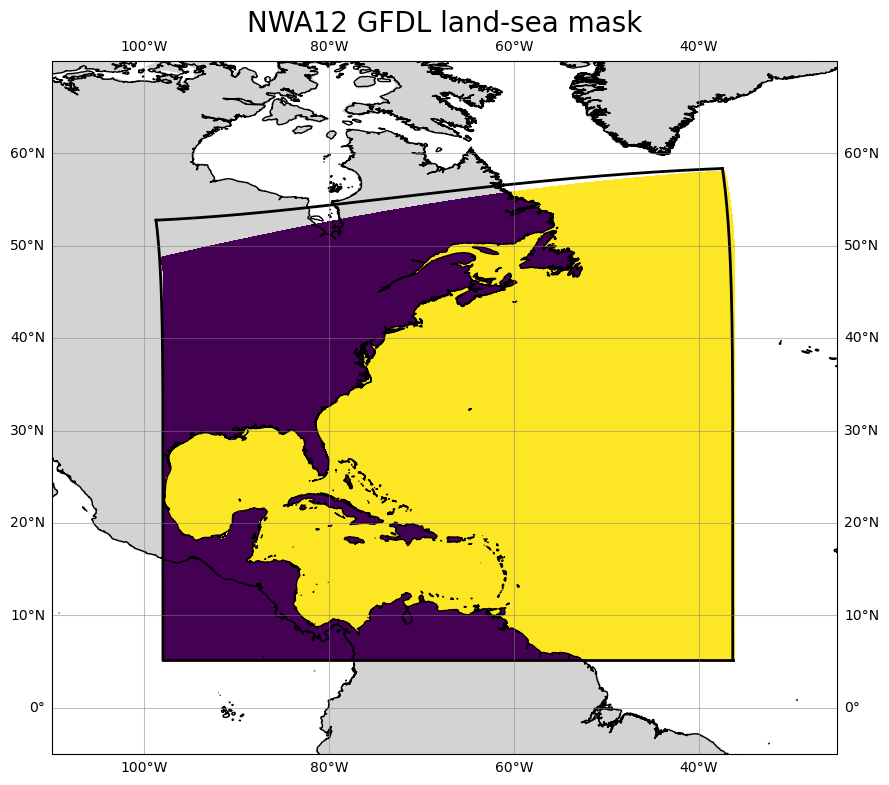

In [12]:
plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)


im = ax.pcolormesh(ds2.tlon, ds2.tlat, ds2.tmask, transform=ccrs.PlateCarree())
#plt.colorbar(im, shrink=0.7, label=r'meter')

ax.plot(ds.qlon[0,:], ds.qlat[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[-1,:], ds.qlat[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[:,0], ds.qlat[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(ds.qlon[:,-1], ds.qlat[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())


plt.title('NWA12 GFDL land-sea mask', fontsize=20)